# Analysis for Results and Discussion
Used local results from eval_results folder

In [122]:
# 1. Import data
import pandas as pd
from pathlib import Path
raw = pd.read_csv(Path("tier1_acl_results.csv"))
raw.head()

,tier,split,talk_id,condition,noise_type,snr_db,noise_seed,wer,cer,kter,term_presence_recall,terms_present,signal_snr_improvement_db,rtf,audio_duration_s,seconds,language
0,1,eval,2022.acl-long.111,arm_a,none,NaN,NaN,0.262058,0.105971,0.840580,0.840580,69,NaN,0.078193,713.015,55.752916,en
1,1,eval,2022.acl-long.111,hp,none,NaN,NaN,0.250000,0.096088,0.840580,0.840580,69,NaN,0.085939,713.015,61.275969,en
2,1,eval,2022.acl-long.111,hp+sg,none,NaN,NaN,0.250000,0.096088,0.840580,0.840580,69,NaN,0.086254,713.015,61.500746,en
3,1,eval,2022.acl-long.111,hp_wiener,none,NaN,NaN,0.250000,0.096088,0.840580,0.840580,69,NaN,0.086714,713.015,61.828386,en
4,1,eval,2022.acl-long.111,hp_wiener_oa,none,NaN,NaN,0.251608,0.095676,0.826087,0.826087,69,NaN,0.086114,713.015,61.400359,en


In [123]:
%matplotlib inline
# 2. Import dependencies
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi": 110})

In [124]:
# 3. Create dataframe
df = raw.copy()
df = df.drop_duplicates()
df["snr_db"] = df["snr_db"].fillna("clean").map(lambda v: "clean" if v == "clean" else str(int(float(v))))
df["noise_seed"] = df["noise_seed"].fillna("clean").astype(str)
df["snr_db"] = pd.Categorical(df["snr_db"], categories=["clean", "20", "10", "5", "0"], ordered=True)
df["snr_num"] = df["snr_db"].astype(str).map({"clean": np.nan, "20": 20.0, "10": 10.0, "5": 5.0, "0": 0.0})
df["condition"] = pd.Categorical(df["condition"], categories=["arm_a", "hp", "hp+sg", "hp_wiener", "hp_wiener_oa", "hp_ffmpeg"], ordered=True)
df = df.drop(columns=["term_presence_recall", "tier", "split", "language"], errors="ignore")
df.head()

C:\Users\Leon\AppData\Local\Temp\ipykernel_25196\1102493549.py:4: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["snr_db"] = df["snr_db"].fillna("clean").map(lambda v: "clean" if v == "clean" else str(int(float(v))))
C:\Users\Leon\AppData\Local\Temp\ipykernel_25196\1102493549.py:5: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df["noise_seed"] = df["noise_seed"].fillna("clean").astype(str)


,talk_id,condition,noise_type,snr_db,noise_seed,wer,cer,kter,terms_present,signal_snr_improvement_db,rtf,audio_duration_s,seconds,snr_num
0,2022.acl-long.111,arm_a,none,clean,clean,0.262058,0.105971,0.840580,69,NaN,0.078193,713.015,55.752916,NaN
1,2022.acl-long.111,hp,none,clean,clean,0.250000,0.096088,0.840580,69,NaN,0.085939,713.015,61.275969,NaN
2,2022.acl-long.111,hp+sg,none,clean,clean,0.250000,0.096088,0.840580,69,NaN,0.086254,713.015,61.500746,NaN
3,2022.acl-long.111,hp_wiener,none,clean,clean,0.250000,0.096088,0.840580,69,NaN,0.086714,713.015,61.828386,NaN
4,2022.acl-long.111,hp_wiener_oa,none,clean,clean,0.251608,0.095676,0.826087,69,NaN,0.086114,713.015,61.400359,NaN


In [125]:
# 4. Explore data
rows_cols = (df.shape, list(df.columns))
grouped = (df.groupby(["condition", "noise_type"], observed=True)["wer"]
              .mean().unstack("noise_type").round(4))
rows_cols, grouped

(((390, 14),
  ['talk_id',
   'condition',
   'noise_type',
   'snr_db',
   'noise_seed',
   'wer',
   'cer',
   'kter',
   'terms_present',
   'signal_snr_improvement_db',
   'rtf',
   'audio_duration_s',
   'seconds',
   'snr_num']),
 noise_type    demand:DKITCHEN  demand:DLIVING  demand:DWASHING    none
 condition                                                             
 arm_a                  0.1984          0.2175           0.1698  0.1696
 hp                     0.1994          0.2130           0.1703  0.1677
 hp+sg                  0.1987          0.2129           0.1703  0.1677
 hp_wiener              0.1994          0.2128           0.1702  0.1677
 hp_wiener_oa           0.1969          0.2179           0.1720  0.1685
 hp_ffmpeg              0.2054          0.2255           0.1770  0.1754)

C:\Users\Leon\AppData\Local\Temp\ipykernel_25196\3353391655.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(q1.index.astype(str), rotation=30, ha="right")


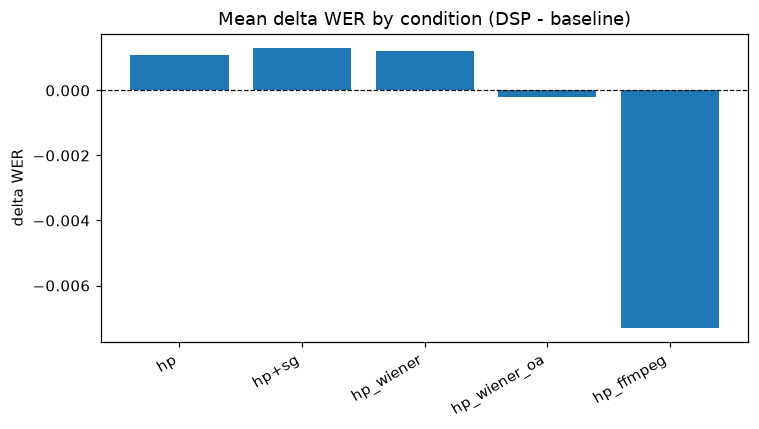

In [126]:
# Q1: Does DSP improve transcription? (paired deltas vs baseline)
keys = ["talk_id", "noise_type", "snr_db", "noise_seed"]
base = (df[df.condition == "arm_a"][keys + ["wer"]]
        .rename(columns={"wer": "wer_base"}))
d = df[df.condition != "arm_a"].merge(base, on=keys, how="left", validate="many_to_one")
d["delta_wer"] = d["wer_base"] - d["wer"]  # flipped: positive = improvement
q1 = (d.groupby("condition", observed=True)
        .agg(mean_delta_wer=("delta_wer", "mean"),
             win_rate=("delta_wer", lambda s: (s > 0).mean()))
        .round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(q1.index.astype(str), q1["mean_delta_wer"])
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Mean delta WER by condition (DSP - baseline)")
ax.set_ylabel("delta WER")
ax.set_xticklabels(q1.index.astype(str), rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [127]:
# Q2: Which DSP combo is most / least impactful?
q2 = (d.groupby("condition", observed=True)["delta_wer"]
        .mean().sort_values(ascending=False).reset_index())
q2.columns = ["condition", "mean_delta_wer"]
q2["rank"] = range(1, len(q2) + 1)
q2.round(4)


,condition,mean_delta_wer,rank
0,hp+sg,0.0013,1
1,hp_wiener,0.0012,2
2,hp,0.0011,3
3,hp_wiener_oa,-0.0002,4
4,hp_ffmpeg,-0.0073,5


In [128]:
# Q3: Mechanism, conditions, and cost
expl = d.copy()
expl["environment"] = np.where(expl["noise_type"].astype(str) == "none", "clean", "noisy")
cost_base = (df[df.condition == "arm_a"][keys + ["rtf"]].rename(columns={"rtf": "rtf_base"}))
expl = expl.merge(cost_base, on=keys, how="left", validate="many_to_one")
expl["delta_rtf"] = expl["rtf"] - expl["rtf_base"]
q3 = (expl.groupby("condition", observed=True)
            .agg(mean_delta_wer=("delta_wer", "mean"),
                 mean_delta_rtf=("delta_rtf", "mean"),
                 win_rate=("delta_wer", lambda s: (s > 0).mean()))
            .round(4))
q3


,mean_delta_wer,mean_delta_rtf,win_rate
condition,,,
hp,0.0011,0.0120,0.4154
hp+sg,0.0013,0.0121,0.4154
hp_wiener,0.0012,0.0119,0.4154
hp_wiener_oa,-0.0002,0.0102,0.4308
hp_ffmpeg,-0.0073,0.0077,0.1385


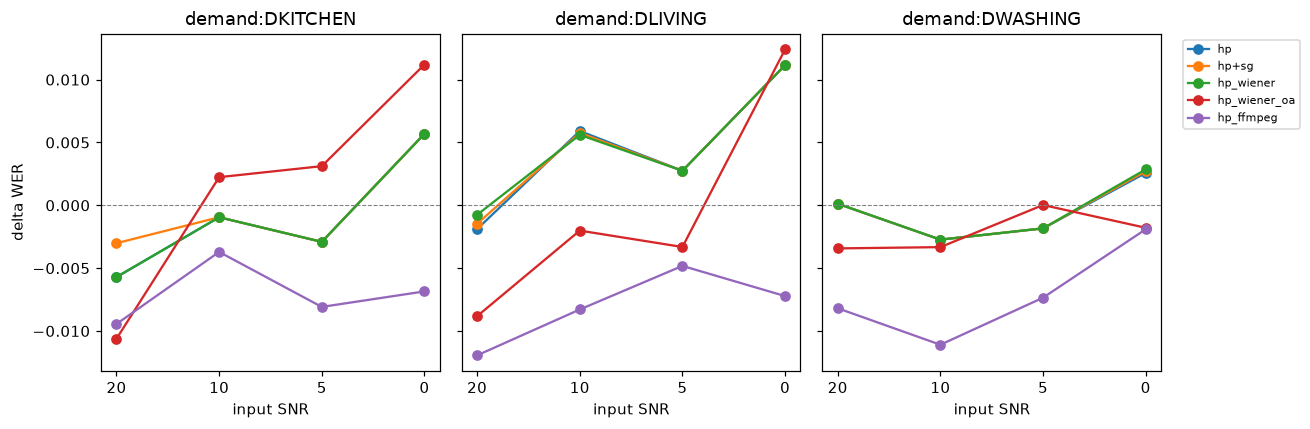

In [129]:
# Q3 (viz): delta WER vs input SNR by noise type
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, nt in zip(axes, ["demand:DKITCHEN", "demand:DLIVING", "demand:DWASHING"]):
    sub = d[d["noise_type"].astype(str) == nt]
    for cond in ["hp", "hp+sg", "hp_wiener", "hp_wiener_oa", "hp_ffmpeg"]:
        g = sub[sub["condition"].astype(str) == cond].groupby("snr_db", observed=True)["delta_wer"].mean()
        ax.plot(g.index.astype(str), g.values, marker="o", label=cond)
    ax.set_title(nt)
    ax.set_xlabel("input SNR")
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.7)
axes[0].set_ylabel("delta WER")
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## A. Spread of the paired deltas (Q1)

Aim: how consistent is the effect across files? Is the mean small relative to the variability?

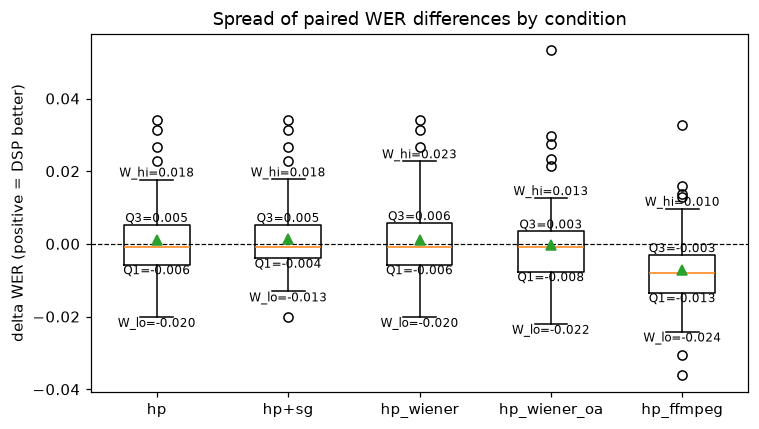

In [130]:
# A. spread of paired deltas
spread = d.groupby("condition", observed=True)["delta_wer"].agg(
    n="size", mean="mean", sd=lambda s: s.std(ddof=1),
    sem=lambda s: s.sem(ddof=1),
    q25=lambda s: s.quantile(0.25), median="median", q75=lambda s: s.quantile(0.75),
    minimum="min", maximum="max",
).reset_index()
spread["iqr"] = spread["q75"] - spread["q25"]
spread["cv_pct"] = (spread["sd"] / spread["mean"].replace(0, np.nan)).abs() * 100
spread = spread[["condition", "n", "mean", "sd", "sem", "cv_pct", "q25", "median", "q75", "iqr", "minimum", "maximum"]].round(4)
spread

fig, ax = plt.subplots(figsize=(7, 4))
dsp_conds = [c for c in d["condition"].cat.categories if c != "arm_a"]
bp = ax.boxplot([d.loc[d["condition"] == c, "delta_wer"].to_numpy(float) for c in dsp_conds],
               tick_labels=dsp_conds, showmeans=True)
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
# annotate box (Q1/Q3) and whisker (non-outlier) edges
for i in range(len(dsp_conds)):
    box_y = bp["boxes"][i].get_ydata()
    q1, q3 = float(min(box_y)), float(max(box_y))
    lo = float(bp["whiskers"][2 * i].get_ydata()[-1])
    hi = float(bp["whiskers"][2 * i + 1].get_ydata()[-1])
    ax.text(i + 1, q3, f"Q3={q3:.3f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + 1, q1, f"Q1={q1:.3f}", ha="center", va="top", fontsize=8)
    ax.text(i + 1, hi, f"W_hi={hi:.3f}", ha="center", va="bottom", fontsize=8)
    ax.text(i + 1, lo, f"W_lo={lo:.3f}", ha="center", va="top", fontsize=8)
ax.set_ylabel("delta WER (positive = DSP better)")
ax.set_title("Spread of paired WER differences by condition")
plt.tight_layout()
plt.show()


Reading it: where SD is an order of magnitude larger than the mean, the average effect is being carried by a mix of small wins and losses; the boxplot shows whether a few extremes dominate.

## B. Cluster bootstrap CI, resampling talk_id (Q1, Q2)

Aim: how much would the average effect change with a different set of talks, and does the plausible range include zero? Only 5 talks, so CIs (especially per SNR) are wide.

In [131]:
# B. reusable cluster bootstrap: resample whole talks
rng = np.random.default_rng(0)

def cluster_ci(g, value_col="delta_wer", cluster_col="talk_id", n_boot=5000):
    clusters = g[cluster_col].unique()
    vals = g[value_col].to_numpy(float)
    cl = g[cluster_col].to_numpy()
    idx_by_cluster = {c: np.where(cl == c)[0] for c in clusters}
    boot = np.empty(n_boot, dtype=float)
    for b in range(n_boot):
        chosen = rng.choice(clusters, size=len(clusters), replace=True)
        rows = np.concatenate([idx_by_cluster[c] for c in chosen])
        boot[b] = vals[rows].mean()
    return float(vals.mean()), float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))

dsp_conds = [c for c in d["condition"].cat.categories if c != "arm_a"]

ci_rows = []
for c in dsp_conds:
    sub = d[d["condition"] == c]
    mean, lo, hi = cluster_ci(sub)
    ci_rows.append({"condition": c, "mean_delta_wer": mean, "ci_lo": lo, "ci_hi": hi,
                    "excludes_zero": bool((lo > 0) or (hi < 0))})
ci_tbl = pd.DataFrame(ci_rows).round(4)
ci_tbl

,condition,mean_delta_wer,ci_lo,ci_hi,excludes_zero
0,hp,0.0011,-0.0014,0.0045,False
1,hp+sg,0.0013,-0.0015,0.0052,False
2,hp_wiener,0.0012,-0.0015,0.0049,False
3,hp_wiener_oa,-0.0002,-0.0030,0.0031,False
4,hp_ffmpeg,-0.0073,-0.0086,-0.0058,True


In [132]:
# B. per condition x input SNR
snr_rows = []
for c in dsp_conds:
    for snr in ["clean", "20", "10", "5", "0"]:
        sub = d[(d["condition"].astype(str) == c) & (d["snr_db"].astype(str) == snr)]
        if len(sub) == 0:
            continue
        mean, lo, hi = cluster_ci(sub)
        snr_rows.append({"condition": c, "snr_db": snr, "n": len(sub),
                         "mean_delta_wer": mean, "ci_lo": lo, "ci_hi": hi,
                         "excludes_zero": bool((lo > 0) or (hi < 0))})
ci_snr = pd.DataFrame(snr_rows).round(4)
ci_snr

,condition,snr_db,n,mean_delta_wer,ci_lo,ci_hi,excludes_zero
0,hp,clean,5,0.0019,-0.0067,0.0106,False
1,hp,20,15,-0.0025,-0.0054,-0.0007,True
2,hp,10,15,0.0007,-0.0039,0.0060,False
3,hp,5,15,-0.0007,-0.0028,0.0020,False
4,hp,0,15,0.0065,-0.0033,0.0177,False
5,hp+sg,clean,5,0.0019,-0.0067,0.0106,False
6,hp+sg,20,15,-0.0015,-0.0052,0.0017,False
7,hp+sg,10,15,0.0007,-0.0040,0.0058,False
8,hp+sg,5,15,-0.0007,-0.0028,0.0020,False
9,hp+sg,0,15,0.0065,-0.0033,0.0178,False


Reading it: a CI containing 0 means the data are compatible with no effect across a different draw of talks; the per-SNR CIs are based on 15 rows each and are necessarily wide.

## C. Paired tests with multiple-comparison correction (Q1, Q2)

Aim: is each improvement bigger than chance, and how big is it in standardized terms? Effect sizes accompany every p-value.

In [133]:
# optional statsmodels import with fallback
try:
    from statsmodels.stats.multitest import multipletests
except Exception:
    def multipletests(pvals, method="holm"):
        p = np.asarray(pvals, dtype=float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        prev = 0.0
        for rank, idx in enumerate(order):
            val = min(1.0, p[idx] * (m - rank))
            val = max(val, prev)
            adj[idx] = val
            prev = val
        return adj, None, None, None

def holm(pvals):
    arr = np.asarray(pvals, dtype=float)
    try:
        from statsmodels.stats.multitest import multipletests as _mp
        return np.asarray(_mp(arr, method="holm")[1], dtype=float)
    except Exception:
        m = len(arr)
        order = np.argsort(arr)
        adj = np.empty(m)
        prev = 0.0
        for rank, idx in enumerate(order):
            val = min(1.0, arr[idx] * (m - rank))
            val = max(val, prev)
            adj[idx] = val
            prev = val
        return adj

def safe_wilcoxon_p(x):
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return np.nan
    if np.all(x == 0):
        return 1.0
    try:
        return float(stats.wilcoxon(x, zero_method="wilcox").pvalue)
    except ValueError:
        return np.nan

t_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_wer"].to_numpy(float)
    sd = x.std(ddof=1)
    tr = stats.ttest_1samp(x, 0.0)
    t_rows.append({"condition": c, "n": len(x), "mean_delta": x.mean(), "sd": sd,
                   "t_pvalue": tr.pvalue, "wilcoxon_p": safe_wilcoxon_p(x),
                   "cohens_dz": (x.mean() / sd if sd > 0 else np.nan)})
t_tbl = pd.DataFrame(t_rows).round(4)
t_tbl["wilcoxon_p_holm"] = holm(t_tbl["wilcoxon_p"].fillna(1.0).to_numpy()).round(4)
t_tbl


,condition,n,mean_delta,sd,t_pvalue,wilcoxon_p,cohens_dz,wilcoxon_p_holm
0,hp,65,0.0011,0.0104,0.4039,0.9804,0.1042,1.0
1,hp+sg,65,0.0013,0.0102,0.3011,0.8361,0.1293,1.0
2,hp_wiener,65,0.0012,0.0105,0.3707,0.8940,0.1118,1.0
3,hp_wiener_oa,65,-0.0002,0.0122,0.8707,0.2655,-0.0203,1.0
4,hp_ffmpeg,65,-0.0073,0.0105,0.0000,0.0000,-0.6916,0.0


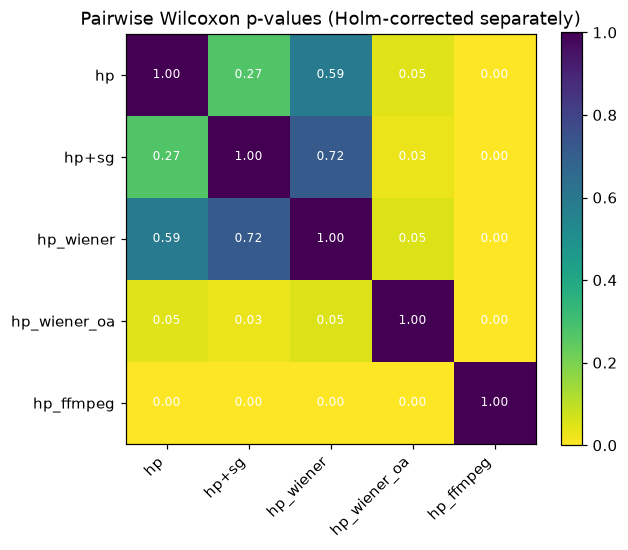

In [134]:
# C. pairwise Wilcoxon between DSP conditions (Holm across 10 pairs) + heatmap
pivot_paired = d.pivot_table(index=["talk_id", "noise_type", "snr_db"], columns="condition", values="delta_wer")
assert not pivot_paired.isna().any().any()

pair_rows = []
p_mat = pd.DataFrame(1.0, index=dsp_conds, columns=dsp_conds)
for i in range(len(dsp_conds)):
    for j in range(i + 1, len(dsp_conds)):
        a, b = dsp_conds[i], dsp_conds[j]
        xa = pivot_paired[a].to_numpy(float)
        xb = pivot_paired[b].to_numpy(float)
        try:
            p = float(stats.wilcoxon(xa, xb, zero_method="wilcox").pvalue)
        except ValueError:
            p = np.nan
        pair_rows.append({"pair": f"{a} vs {b}", "mean_diff_a_minus_b": float(np.mean(xa - xb)), "p_raw": p})
        p_mat.loc[a, b] = p
        p_mat.loc[b, a] = p

pair_tbl = pd.DataFrame(pair_rows)
pair_tbl["p_holm"] = holm(pair_tbl["p_raw"].fillna(1.0).to_numpy())
pair_tbl = pair_tbl.round(4)
pair_tbl

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(p_mat.to_numpy(dtype=float), vmin=0, vmax=1, cmap="viridis_r")
ax.set_xticks(range(len(dsp_conds)))
ax.set_yticks(range(len(dsp_conds)))
ax.set_xticklabels(dsp_conds, rotation=45, ha="right")
ax.set_yticklabels(dsp_conds)
for i in range(len(dsp_conds)):
    for j in range(len(dsp_conds)):
        ax.text(j, i, f"{p_mat.iloc[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
ax.set_title("Pairwise Wilcoxon p-values (Holm-corrected separately)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


Reading it: compare each Wilcoxon p (Holm) with its Cohen's dz and cluster CI; a consistent, small effect can be real yet practically modest.

## D. Equivalence test, TOST (Q1)

Aim: when no significant difference is found, can we positively claim the effect is practically negligible?

In [135]:
# D. TOST equivalence test (margin = 0.5 pp WER, a judgment call)
margin = 0.005

def tost_p(x, m):
    p1 = stats.ttest_1samp(x, -m, alternative="greater").pvalue
    p2 = stats.ttest_1samp(x, m, alternative="less").pvalue
    return float(max(p1, p2))

tost_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_wer"].to_numpy(float)
    p = tost_p(x, margin)
    tost_rows.append({"condition": c, "margin": margin, "tost_p": p,
                      "verdict": "equivalent within ±margin" if p < 0.05 else "inconclusive/not equivalent"})
tost_tbl = pd.DataFrame(tost_rows).round(4)
tost_tbl

,condition,margin,tost_p,verdict
0,hp,0.005,0.0018,equivalent within ±margin
1,hp+sg,0.005,0.0026,equivalent within ±margin
2,hp_wiener,0.005,0.0022,equivalent within ±margin
3,hp_wiener_oa,0.005,0.0013,equivalent within ±margin
4,hp_ffmpeg,0.005,0.9573,inconclusive/not equivalent


In [136]:
# D. sensitivity of TOST to the margin
sens_rows = []
for m in [0.0025, 0.005, 0.010]:
    for c in dsp_conds:
        x = d.loc[d["condition"] == c, "delta_wer"].to_numpy(float)
        sens_rows.append({"margin": m, "condition": c, "tost_p": tost_p(x, m),
                          "verdict": "equivalent" if tost_p(x, m) < 0.05 else "not equivalent"})
sens_tbl = pd.DataFrame(sens_rows).round(4)
sens_tbl

,margin,condition,tost_p,verdict
0,0.0025,hp,0.1390,not equivalent
1,0.0025,hp+sg,0.1794,not equivalent
2,0.0025,hp_wiener,0.1552,not equivalent
3,0.0025,hp_wiener_oa,0.0711,not equivalent
4,0.0025,hp_ffmpeg,0.9997,not equivalent
5,0.0050,hp,0.0018,equivalent
6,0.0050,hp+sg,0.0026,equivalent
7,0.0050,hp_wiener,0.0022,equivalent
8,0.0050,hp_wiener_oa,0.0013,equivalent
9,0.0050,hp_ffmpeg,0.9573,not equivalent


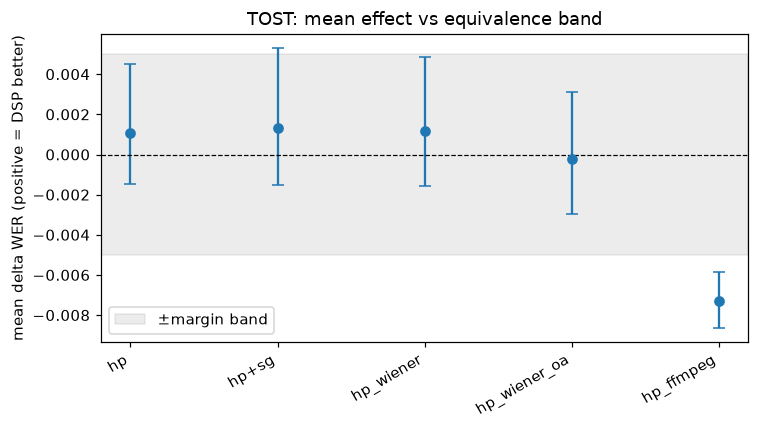

In [137]:
# D. plot mean with CI against the ±margin band
fig, ax = plt.subplots(figsize=(7, 4))
xs = range(len(dsp_conds))
means = [cluster_ci(d[d["condition"] == c])[0] for c in dsp_conds]
los = [cluster_ci(d[d["condition"] == c])[1] for c in dsp_conds]
his = [cluster_ci(d[d["condition"] == c])[2] for c in dsp_conds]
errs = np.vstack([np.array(means) - np.array(los), np.array(his) - np.array(means)])
ax.errorbar(xs, means, yerr=errs, fmt="o", capsize=4)
ax.axhspan(-margin, margin, color="grey", alpha=0.15, label="±margin band")
ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xticks(xs)
ax.set_xticklabels(dsp_conds, rotation=30, ha="right")
ax.set_ylabel("mean delta WER (positive = DSP better)")
ax.set_title("TOST: mean effect vs equivalence band")
ax.legend()
plt.tight_layout()
plt.show()

Reading it: a condition whose CI also sits well inside ±margin strengthens the “no practical effect” claim beyond a plain nonsignificant test.

## E. Sign test on wins/losses (Q1, Q2)

Aim: ignoring magnitude, do wins and losses split 50/50?

In [138]:
# E. sign test
sign_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_wer"]
    wins = int((x > 0).sum())
    losses = int((x < 0).sum())
    ties = int((x == 0).sum())
    n_eff = wins + losses
    p = stats.binomtest(wins, n_eff).pvalue if n_eff > 0 else np.nan
    sign_rows.append({"condition": c, "wins": wins, "losses": losses, "ties": ties,
                     "n_eff": n_eff, "p_value": p})
sign_tbl = pd.DataFrame(sign_rows).round(4)
sign_tbl["p_holm"] = holm(sign_tbl["p_value"].fillna(1.0).to_numpy()).round(4)
sign_tbl


,condition,wins,losses,ties,n_eff,p_value,p_holm
0,hp,27,35,3,62,0.3742,1.0
1,hp+sg,27,35,3,62,0.3742,1.0
2,hp_wiener,27,35,3,62,0.3742,1.0
3,hp_wiener_oa,28,36,1,64,0.3817,1.0
4,hp_ffmpeg,9,55,1,64,0.0000,0.0


Reading it: ties carry no directional information and are excluded from the count; this guards against large outliers driving the mean.

## F. Omnibus test and ranking (Q2)

Aim: do the conditions differ from each other at all, so that a ranking is justified?

In [139]:
# F. pivot + Friedman
pivot_fw = d.pivot_table(index=["talk_id", "noise_type", "snr_db"], columns="condition", values="delta_wer")
assert not pivot_fw.isna().any().any()
assert pivot_fw.shape[0] == 65

friedman = stats.friedmanchisquare(*[pivot_fw[c].to_numpy() for c in pivot_fw.columns])
print("Friedman statistic:", round(float(friedman.statistic), 4), "p:", friedman.pvalue)

# re-run without hp_ffmpeg to see if one condition drives it
friedman_no_ff = stats.friedmanchisquare(*[pivot_fw[c].to_numpy() for c in pivot_fw.columns if c != "hp_ffmpeg"])
print("Without hp_ffmpeg: statistic:", round(float(friedman_no_ff.statistic), 4), "p:", friedman_no_ff.pvalue)

# rank stability: best/worst per scenario
best_counts = pivot_fw.idxmax(axis=1).value_counts()
worst_counts = pivot_fw.idxmin(axis=1).value_counts()
best_worst = pd.DataFrame({"best_scenarios": best_counts, "worst_scenarios": worst_counts}).fillna(0).astype(int)
best_worst

Friedman statistic: 61.8768 p: 1.1693104959987273e-12
Without hp_ffmpeg: statistic: 21.6553 p: 7.694169733660626e-05


,best_scenarios,worst_scenarios
arm_a,0,0
hp,39,10
hp+sg,1,0
hp_wiener,2,0
hp_wiener_oa,17,18
hp_ffmpeg,6,37


In [140]:
# F. rank table with CI columns attached
rank_with_ci = q2.merge(ci_tbl[["condition", "ci_lo", "ci_hi"]], on="condition", how="left") if "q2" in globals() else None
if rank_with_ci is None:
    rank_with_ci = pivot_fw.mean().sort_values(ascending=False).reset_index()
    rank_with_ci.columns = ["condition", "mean_delta_wer"]
    rank_with_ci = rank_with_ci.merge(ci_tbl[["condition", "ci_lo", "ci_hi"]], on="condition", how="left")
rank_with_ci.round(4)

,condition,mean_delta_wer,rank,ci_lo,ci_hi
0,hp+sg,0.0013,1,-0.0015,0.0052
1,hp_wiener,0.0012,2,-0.0015,0.0049
2,hp,0.0011,3,-0.0014,0.0045
3,hp_wiener_oa,-0.0002,4,-0.0030,0.0031
4,hp_ffmpeg,-0.0073,5,-0.0086,-0.0058


Note: if the Friedman result is driven by one extreme condition (hp_ffmpeg), interpret the full ranking cautiously; the without-hp_ffmpeg re-run above is reported for that reason.

## G. Variance decomposition and mixed model (Q2, Q3)

Aim: where does the variation come from (DSP, talk, noise type, SNR, residual)?

In [141]:
# G. mixed models (warnings suppressed; talk variance may be near zero)
import warnings
try:
    import statsmodels.formula.api as smf
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m1 = smf.mixedlm("delta_wer ~ C(condition)", d, groups=d["talk_id"]).fit(reml=False)
    print(m1.summary())
    print("talk (group) variance:", m1.cov_re)
except Exception as e:
    print("Mixed model unavailable/failed:", repr(e))

# Q3 model on noisy rows only (clean rows dropped where snr_num is NaN)
noisy = d[d["snr_num"].notna()].copy()
dropped = len(d) - len(noisy)
print(f"clean rows dropped for the SNR model: {dropped}")
try:
    import statsmodels.formula.api as smf
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m2 = smf.mixedlm("delta_wer ~ C(condition) * snr_num", noisy, groups=noisy["talk_id"]).fit(reml=False)
    print(m2.summary())
except Exception as e:
    print("Noisy-row mixed model unavailable/failed:", repr(e))

Mixed model unavailable/failed: LinAlgError('Singular matrix')
clean rows dropped for the SNR model: 25
Noisy-row mixed model unavailable/failed: LinAlgError('Singular matrix')


In [142]:
# G. eta-squared from a type-2 ANOVA + per-condition SNR crossover
try:
    from statsmodels.formula.api import ols
    from statsmodels.stats.anova import anova_lm
    model = ols("delta_wer ~ C(condition) + C(talk_id) + C(noise_type) + C(snr_db)", data=d).fit()
    aov = anova_lm(model, typ=2)
    aov["eta_sq"] = aov["sum_sq"] / aov["sum_sq"].sum()
    display(aov.round(4))
except Exception as e:
    print("ANOVA unavailable/failed:", repr(e))

cross_rows = []
for c in dsp_conds:
    g = d[d["condition"].astype(str) == c].groupby("snr_num", observed=True)["delta_wer"].mean().sort_index()
    xs = g.index.to_numpy(dtype=float)
    ys = g.to_numpy(dtype=float)
    mask = np.isfinite(xs) & np.isfinite(ys)
    xs, ys = xs[mask], ys[mask]
    cross = np.nan
    for i in range(len(xs) - 1):
        if ys[i] == 0:
            cross = xs[i]
            break
        if ys[i] * ys[i + 1] < 0:
            cross = xs[i] + (0 - ys[i]) * (xs[i + 1] - xs[i]) / (ys[i + 1] - ys[i])
            break
    cross_rows.append({"condition": c, "snr_crossover": cross})
cross_tbl = pd.DataFrame(cross_rows).round(4)
cross_tbl

C:\Users\Leon\AppData\Local\Temp\ipykernel_25196\3173663204.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = ols("delta_wer ~ C(condition) + C(talk_id) + C(noise_type) + C(snr_db)", data=d).fit()


,sum_sq,df,F,PR(>F),eta_sq
C(condition),0.0038,5.0,7.5312,0.0000,0.0912
C(talk_id),0.0026,4.0,6.4458,0.0001,0.0624
C(noise_type),0.0006,3.0,1.9384,0.1233,0.0141
C(snr_db),0.0034,4.0,8.4327,0.0000,0.0817
Residual,0.0310,310.0,NaN,NaN,0.7506


,condition,snr_crossover
0,hp,4.5334
1,hp+sg,4.5364
2,hp_wiener,4.5395
3,hp_wiener_oa,4.9598
4,hp_ffmpeg,NaN


Reading it: the condition and talk effects should be read together—talk identity typically explains more variance than DSP choice—and the SNR crossover states where a condition’s mean benefit changes sign.

## H. Mechanism correlation (Q3)

Aim: does cleaning the signal actually predict better transcription? Note `signal_snr_improvement_db` is also nonzero for `arm_a`; a baseline-adjusted sensitivity version is shown.

raw DSP-reported SNR gain: rho=0.2846, p=5.339e-07, n=300
  hp: rho=0.0330, p=0.8026, n=60
  hp+sg: rho=-0.0084, p=0.9493, n=60
  hp_wiener: rho=0.0166, p=0.9, n=60
  hp_wiener_oa: rho=0.2345, p=0.07137, n=60
  hp_ffmpeg: rho=0.1407, p=0.2835, n=60
baseline-adjusted incremental gain: rho=0.2846, p=5.339e-07, n=300
  hp: rho=0.0330, p=0.8026, n=60
  hp+sg: rho=-0.0084, p=0.9493, n=60
  hp_wiener: rho=0.0166, p=0.9, n=60
  hp_wiener_oa: rho=0.2345, p=0.07137, n=60
  hp_ffmpeg: rho=0.1407, p=0.2835, n=60


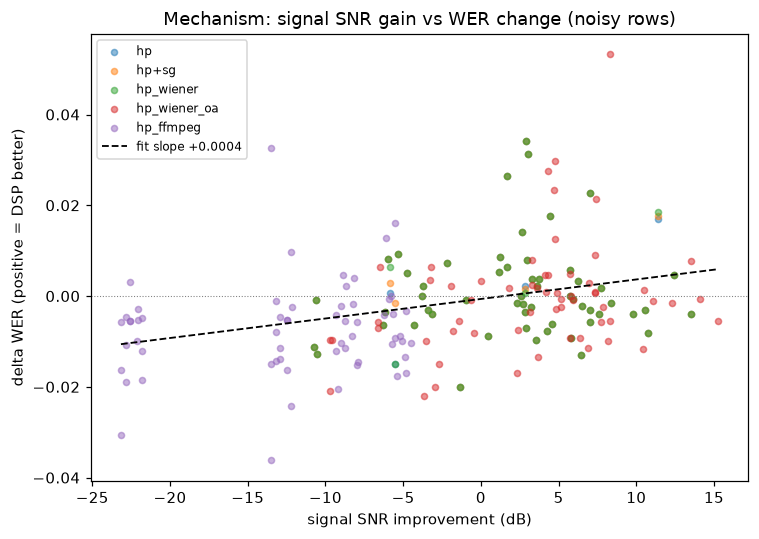

In [143]:
# H. spearman correlation: signal SNR improvement vs delta WER
noisy_h = d[d["noise_type"].astype(str) != "none"].copy()
base_snr = (df[df["condition"].astype(str) == "arm_a"][keys + ["signal_snr_improvement_db"]]
            .rename(columns={"signal_snr_improvement_db": "base_snr_gain"}))
noisy_h = noisy_h.merge(base_snr, on=keys, how="left", validate="many_to_one")
noisy_h["incr_snr_gain"] = noisy_h["signal_snr_improvement_db"] - noisy_h["base_snr_gain"]

def corr_report(xcol, label):
    rho, p = stats.spearmanr(noisy_h[xcol], noisy_h["delta_wer"], nan_policy="omit")
    print(f"{label}: rho={rho:.4f}, p={p:.4g}, n={int(noisy_h[xcol].notna().sum())}")
    for c in dsp_conds:
        sub = noisy_h[noisy_h["condition"].astype(str) == c]
        r, pp = stats.spearmanr(sub[xcol], sub["delta_wer"], nan_policy="omit")
        print(f"  {c}: rho={r:.4f}, p={pp:.4g}, n={int(sub[xcol].notna().sum())}")

corr_report("signal_snr_improvement_db", "raw DSP-reported SNR gain")
corr_report("incr_snr_gain", "baseline-adjusted incremental gain")

fig, ax = plt.subplots(figsize=(7, 5))
for i, c in enumerate(dsp_conds):
    sub = noisy_h[noisy_h["condition"].astype(str) == c]
    ax.scatter(sub["signal_snr_improvement_db"], sub["delta_wer"], s=16,
               color=plt.cm.tab10(i), label=c, alpha=0.5)
x = noisy_h["signal_snr_improvement_db"].to_numpy(float)
y = noisy_h["delta_wer"].to_numpy(float)
mask = np.isfinite(x) & np.isfinite(y)
if mask.sum() >= 2:
    m, b = np.polyfit(x[mask], y[mask], 1)
    xs = np.linspace(np.nanmin(x), np.nanmax(x), 100)
    ax.plot(xs, m * xs + b, color="black", linestyle="--", linewidth=1.2, label=f"fit slope {m:+.4f}")
ax.axhline(0, color="grey", linestyle=":", linewidth=0.7)
ax.set_xlabel("signal SNR improvement (dB)")
ax.set_ylabel("delta WER (positive = DSP better)")
ax.set_title("Mechanism: signal SNR gain vs WER change (noisy rows)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Reading it: a positive association supports “cleaner signal → better transcription”; a null or reversed association means the ASR is already robust or the SNR metric does not capture what matters.

## I. Summary table

One consolidated table, saved to `results_summary.csv`.

In [144]:
# I. consolidated summary
final_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_wer"].to_numpy(float)
    sd = x.std(ddof=1)
    mean, lo, hi = cluster_ci(d[d["condition"] == c])
    w_p = safe_wilcoxon_p(x) if False else None
    # reuse safe function
    def _wp(a):
        a = np.asarray(a, float)
        if len(a) == 0: return np.nan
        if np.all(a == 0): return 1.0
        try: return float(stats.wilcoxon(a, zero_method="wilcox").pvalue)
        except ValueError: return np.nan
    w_p = _wp(x)
    w_p_holm = float(holm([w_p])[0]) if np.isfinite(w_p) else np.nan
    t_p = stats.ttest_1samp(x, 0.0).pvalue
    tost = tost_p(x, 0.005)
    wins = int((x > 0).sum()); losses = int((x < 0).sum()); ties = int((x == 0).sum())
    # mean extra RTF (DSP - baseline)
    rtf_base = df[df["condition"].astype(str) == "arm_a"][keys + ["rtf"]].rename(columns={"rtf": "rtf_base"})
    dd = df[df["condition"].astype(str) == c].merge(rtf_base, on=keys, how="left", validate="many_to_one")
    mean_drtf = float((dd["rtf"] - dd["rtf_base"]).mean())
    final_rows.append({"condition": c, "mean_delta_wer": mean, "sd_delta_wer": sd,
                       "ci_lo": lo, "ci_hi": hi, "ci_excludes_zero": bool((lo > 0) or (hi < 0)),
                       "wilcoxon_p": w_p, "wilcoxon_p_holm": w_p_holm,
                       "cohens_dz": (mean / sd if sd > 0 else np.nan),
                       "tost_p_margin_0.005": tost,
                       "wins": wins, "losses": losses, "ties": ties,
                       "mean_delta_rtf_extra": mean_drtf})

final_tbl = pd.DataFrame(final_rows).round(4)
final_tbl.to_csv("results_summary.csv", index=False)
final_tbl


,condition,mean_delta_wer,sd_delta_wer,ci_lo,ci_hi,ci_excludes_zero,wilcoxon_p,wilcoxon_p_holm,cohens_dz,tost_p_margin_0.005,wins,losses,ties,mean_delta_rtf_extra
0,hp,0.0011,0.0104,-0.0015,0.0045,False,0.9804,0.9804,0.1042,0.0018,27,35,3,0.0120
1,hp+sg,0.0013,0.0102,-0.0015,0.0052,False,0.8361,0.8361,0.1293,0.0026,27,35,3,0.0121
2,hp_wiener,0.0012,0.0105,-0.0016,0.0049,False,0.8940,0.8940,0.1118,0.0022,27,35,3,0.0119
3,hp_wiener_oa,-0.0002,0.0122,-0.0030,0.0031,False,0.2655,0.2655,-0.0203,0.0013,28,36,1,0.0102
4,hp_ffmpeg,-0.0073,0.0105,-0.0086,-0.0059,True,0.0000,0.0000,-0.6916,0.9573,9,55,1,0.0077


# 1. Transcription accuracy (WER and CER)

Both WER and CER use the same paired design; positive = DSP better.

In [145]:
# 1. accuracy data prep: delta_cer and delta_kter (same merge keys as delta_wer)
cer_base = df[df["condition"].astype(str) == "arm_a"][keys + ["cer"]].rename(columns={"cer": "cer_base"})
d = d.merge(cer_base, on=keys, how="left", validate="many_to_one")
d["delta_cer"] = d["cer_base"] - d["cer"]

kter_base = df[df["condition"].astype(str) == "arm_a"][keys + ["kter"]].rename(columns={"kter": "kter_base"})
d = d.merge(kter_base, on=keys, how="left", validate="many_to_one")
d["delta_kter"] = d["kter_base"] - d["kter"]

assert d["delta_cer"].notna().all()
assert d["delta_kter"].notna().all()
print("paired rows per condition:", d.groupby("condition", observed=True).size().to_dict())
print("raw vs adjusted agreement will be checked below.")

# marginal convention check (positive = improvement)
assert (d["delta_wer"] == d["wer_base"] - d["wer"]).all()
assert (d["delta_cer"] == d["cer_base"] - d["cer"]).all()

paired rows per condition: {'hp': 65, 'hp+sg': 65, 'hp_wiener': 65, 'hp_wiener_oa': 65, 'hp_ffmpeg': 65}
raw vs adjusted agreement will be checked below.


In [146]:
# 1. helper: metric-level spread table (used for WER and CER)
def spread_for_metric(metric):
    col = f"delta_{metric}"
    out = d.groupby("condition", observed=True)[col].agg(
        n="size", mean="mean", sd=lambda s: s.std(ddof=1), sem=lambda s: s.sem(ddof=1),
        q25=lambda s: s.quantile(0.25), median="median", q75=lambda s: s.quantile(0.75),
        minimum="min", maximum="max",
    ).reset_index()
    out["iqr"] = out["q75"] - out["q25"]
    out["cv_pct"] = (out["sd"] / out["mean"].replace(0, np.nan)).abs() * 100
    return out.round(4)

acc_spread_wer = spread_for_metric("wer")
acc_spread_cer = spread_for_metric("cer")
acc_spread_wer, acc_spread_cer

(      condition   n    mean      sd     sem     q25  median     q75  minimum  \
 0            hp  65  0.0011  0.0104  0.0013 -0.0058 -0.0008  0.0052  -0.0201   
 1         hp+sg  65  0.0013  0.0102  0.0013 -0.0040 -0.0008  0.0052  -0.0201   
 2     hp_wiener  65  0.0012  0.0105  0.0013 -0.0058 -0.0008  0.0057  -0.0201   
 3  hp_wiener_oa  65 -0.0002  0.0122  0.0015 -0.0077 -0.0008  0.0034  -0.0220   
 4     hp_ffmpeg  65 -0.0073  0.0105  0.0013 -0.0135 -0.0080 -0.0031  -0.0362   
 
    maximum     iqr     cv_pct  
 0   0.0341  0.0110   959.5915  
 1   0.0341  0.0092   773.3021  
 2   0.0341  0.0115   894.2384  
 3   0.0532  0.0111  4932.7450  
 4   0.0326  0.0104   144.5993  ,
       condition   n    mean      sd     sem     q25  median     q75  minimum  \
 0            hp  65  0.0009  0.0065  0.0008 -0.0026 -0.0002  0.0026  -0.0102   
 1         hp+sg  65  0.0012  0.0064  0.0008 -0.0021  0.0000  0.0035  -0.0102   
 2     hp_wiener  65  0.0010  0.0065  0.0008 -0.0022 -0.0002  0.0026  

In [147]:
# 1. side-by-side accuracy summary: WER vs CER
WER_MARGIN, CER_MARGIN = 0.005, 0.0025  # judgment calls, percentages of WER/CER

acc_rows = []
for metric, margin in [("wer", WER_MARGIN), ("cer", CER_MARGIN)]:
    col = f"delta_{metric}"
    for c in dsp_conds:
        x = d.loc[d["condition"] == c, col].to_numpy(float)
        sd = x.std(ddof=1)
        mean, lo, hi = cluster_ci(d[d["condition"] == c], value_col=col)
        tr = stats.ttest_1samp(x, 0.0)
        wp = safe_wilcoxon_p(x)
        tost = tost_p(x, margin)
        acc_rows.append({
            "metric": metric.upper(), "condition": c,
            "mean_delta": mean, "sd": sd, "ci_lo": lo, "ci_hi": hi,
            "wilcoxon_p": wp, "wilcoxon_p_holm": np.nan,
            "cohens_dz": (mean / sd if sd > 0 else np.nan),
            "tost_p": tost,
            "tost_verdict": "equivalent within margin" if tost < 0.05 else "inconclusive",
        })
acc_tbl = pd.DataFrame(acc_rows)
# Holm across all (metric, condition) tests
acc_tbl["wilcoxon_p_holm"] = holm(acc_tbl["wilcoxon_p"].fillna(1.0).to_numpy()).round(4)
acc_pivot = acc_tbl.pivot(index="condition", columns="metric", values=["mean_delta", "ci_lo", "ci_hi", "wilcoxon_p_holm", "cohens_dz", "tost_verdict"])
acc_tbl.round(4), acc_pivot.round(4)

(  metric     condition  mean_delta      sd   ci_lo   ci_hi  wilcoxon_p  \
 0    WER            hp      0.0011  0.0104 -0.0015  0.0045      0.9804   
 1    WER         hp+sg      0.0013  0.0102 -0.0015  0.0052      0.8361   
 2    WER     hp_wiener      0.0012  0.0105 -0.0015  0.0049      0.8940   
 3    WER  hp_wiener_oa     -0.0002  0.0122 -0.0030  0.0031      0.2655   
 4    WER     hp_ffmpeg     -0.0073  0.0105 -0.0086 -0.0058      0.0000   
 5    CER            hp      0.0009  0.0065 -0.0005  0.0023      0.8830   
 6    CER         hp+sg      0.0012  0.0064 -0.0006  0.0029      0.5296   
 7    CER     hp_wiener      0.0010  0.0065 -0.0006  0.0025      0.7507   
 8    CER  hp_wiener_oa      0.0004  0.0074 -0.0007  0.0015      0.7006   
 9    CER     hp_ffmpeg     -0.0041  0.0078 -0.0066 -0.0026      0.0000   
 
    wilcoxon_p_holm  cohens_dz  tost_p              tost_verdict  
 0              1.0     0.1042  0.0018  equivalent within margin  
 1              1.0     0.1293  0.0026 

In [148]:
# 1. WER vs CER agreement
agg = d.groupby("condition", observed=True).agg(mean_dwer=("delta_wer", "mean"), mean_dcer=("delta_cer", "mean"))
agg["mean_dwer"] = agg["mean_dwer"].round(4)
agg["mean_dcer"] = agg["mean_dcer"].round(4)
agg["same_direction"] = np.sign(agg["mean_dwer"]) == np.sign(agg["mean_dcer"])
rho_wc, p_wc = stats.spearmanr(d["delta_wer"], d["delta_cer"])
print("Spearman correlation delta_wer vs delta_cer:", round(float(rho_wc), 4), "p:", p_wc)
print("Per-condition agreement:")
agg

Spearman correlation delta_wer vs delta_cer: 0.7289 p: 4.311089369920317e-55
Per-condition agreement:


,mean_dwer,mean_dcer,same_direction
condition,,,
hp,0.0011,0.0009,True
hp+sg,0.0013,0.0012,True
hp_wiener,0.0012,0.0010,True
hp_wiener_oa,-0.0002,0.0004,False
hp_ffmpeg,-0.0073,-0.0041,True


In [149]:
# 1. KTER (secondary) CI summary
kter_rows = []
for c in dsp_conds:
    x = d.loc[d["condition"] == c, "delta_kter"].to_numpy(float)
    mean, lo, hi = cluster_ci(d[d["condition"] == c], value_col="delta_kter")
    kter_rows.append({"condition": c, "mean_delta_kter": mean, "ci_lo": lo, "ci_hi": hi,
                      "n": len(x)})
kter_tbl = pd.DataFrame(kter_rows).round(4)
kter_tbl

,condition,mean_delta_kter,ci_lo,ci_hi,n
0,hp,-0.0035,-0.0119,0.0049,65
1,hp+sg,-0.0040,-0.0126,0.0046,65
2,hp_wiener,-0.0036,-0.0122,0.0049,65
3,hp_wiener_oa,0.0001,-0.0120,0.0070,65
4,hp_ffmpeg,0.0109,0.0026,0.0183,65


### Takeaway — Transcription accuracy
WER and CER results are shown per condition in `acc_tbl` (stable sign convention: positive = DSP improvement). The Spearman and per-condition agreement table above states whether the two metrics agree on direction and significance. KTER is included as a secondary term-recall metric.`

# 2. Audio-enhancement effectiveness (SNR improvement)

`signal_snr_improvement_db` is NaN for clean rows; noisy rows only. Positive gain = DSP reports more improvement than arm_a (baseline).

In [150]:
# 2. noisy rows + data prep for snr gain
snr = df[df["noise_type"].astype(str) != "none"].copy()
print("noisy rows used:", len(snr), "clean rows excluded:", len(df) - len(snr))

# baseline-adjusted (paired) gain on merge keys
snr_base = (df[df["condition"].astype(str) == "arm_a"][keys + ["signal_snr_improvement_db"]]
            .rename(columns={"signal_snr_improvement_db": "snr_gain_base"}))
snr_all = df[df["condition"].astype(str) != "arm_a"].merge(snr_base, on=keys, how="left", validate="many_to_one")
snr_all["snr_gain"] = snr_all["signal_snr_improvement_db"]
snr_all["snr_gain_delta"] = snr_all["snr_gain"] - snr_all["snr_gain_base"]

snr_noisy = snr_all[snr_all["noise_type"].astype(str) != "none"].copy()
print("snr_all noisy rows:", len(snr_noisy))

noisy rows used: 360 clean rows excluded: 30
snr_all noisy rows: 300


In [151]:
# 2. descriptive snr gain per condition
snr_desc = snr_noisy.groupby("condition", observed=True)["snr_gain"].agg(
    n="size", mean="mean", sd=lambda s: s.std(ddof=1), sem=lambda s: s.sem(ddof=1),
    median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
    minimum="min", maximum="max",
).reset_index()
snr_desc["iqr"] = snr_desc["q75"] - snr_desc["q25"]
snr_desc.round(4)

,condition,n,mean,sd,sem,median,q25,q75,minimum,maximum,iqr
0,hp,60,2.0948,5.7768,0.7458,2.8896,-2.4218,6.0124,-10.7113,13.5288,8.4341
1,hp+sg,60,2.0948,5.7768,0.7458,2.8896,-2.4218,6.0124,-10.7113,13.5288,8.4341
2,hp_wiener,60,2.0948,5.7768,0.7458,2.8896,-2.4218,6.0124,-10.7113,13.5288,8.4341
3,hp_wiener_oa,60,3.3483,5.8836,0.7596,4.5158,-0.8537,7.3221,-9.6970,15.2654,8.1758
4,hp_ffmpeg,60,-12.3429,6.5007,0.8392,-10.7412,-15.5961,-7.4761,-23.1550,-4.4915,8.1200


In [152]:
# 2. breakdown: mean gain by condition x input SNR, with cluster CI
rows = []
for c in dsp_conds:
    for snr in ["20", "10", "5", "0"]:
        sub = snr_noisy[(snr_noisy["condition"].astype(str) == c) & (snr_noisy["snr_db"].astype(str) == snr)]
        if len(sub) == 0:
            continue
        mean, lo, hi = cluster_ci(sub, value_col="snr_gain", cluster_col="talk_id")
        rows.append({"condition": c, "snr_db": snr, "n": len(sub),
                     "mean_snr_gain": mean, "ci_lo": lo, "ci_hi": hi})
snr_gain_snr = pd.DataFrame(rows).round(4)
snr_gain_snr

,condition,snr_db,n,mean_snr_gain,ci_lo,ci_hi
0,hp,20,15,-6.0097,-8.4584,-4.1443
1,hp,10,15,2.4177,0.3296,3.9074
2,hp,5,15,5.2746,3.5189,6.5345
3,hp,0,15,6.6965,5.3099,7.6807
4,hp+sg,20,15,-6.0097,-8.4584,-4.1443
5,hp+sg,10,15,2.4177,0.3296,3.9978
6,hp+sg,5,15,5.2746,3.5189,6.4872
7,hp+sg,0,15,6.6965,5.3501,7.6807
8,hp_wiener,20,15,-6.0097,-8.3405,-4.1443
9,hp_wiener,10,15,2.4177,0.3296,3.9074


In [153]:
# 2. breakdown: mean gain by condition x noise_type
rows = []
for c in dsp_conds:
    for nt in snr_noisy["noise_type"].astype(str).unique():
        sub = snr_noisy[(snr_noisy["condition"].astype(str) == c) & (snr_noisy["noise_type"].astype(str) == nt)]
        if len(sub) == 0:
            continue
        mean, lo, hi = cluster_ci(sub, value_col="snr_gain", cluster_col="talk_id")
        rows.append({"condition": c, "noise_type": nt, "n": len(sub),
                     "mean_snr_gain": mean, "ci_lo": lo, "ci_hi": hi})
snr_gain_nt = pd.DataFrame(rows).round(4)
snr_gain_nt

,condition,noise_type,n,mean_snr_gain,ci_lo,ci_hi
0,hp,demand:DKITCHEN,20,2.0915,0.2720,3.3073
1,hp,demand:DLIVING,20,-0.0206,-1.4518,1.0232
2,hp,demand:DWASHING,20,4.2135,1.7127,6.1138
3,hp+sg,demand:DKITCHEN,20,2.0915,0.2641,3.4042
4,hp+sg,demand:DLIVING,20,-0.0206,-1.4518,1.0232
5,hp+sg,demand:DWASHING,20,4.2135,1.7127,6.1138
6,hp_wiener,demand:DKITCHEN,20,2.0915,0.3258,3.4042
7,hp_wiener,demand:DLIVING,20,-0.0206,-1.4518,1.0232
8,hp_wiener,demand:DWASHING,20,4.2135,1.7127,6.1138
9,hp_wiener_oa,demand:DKITCHEN,20,3.0599,1.2857,4.4999


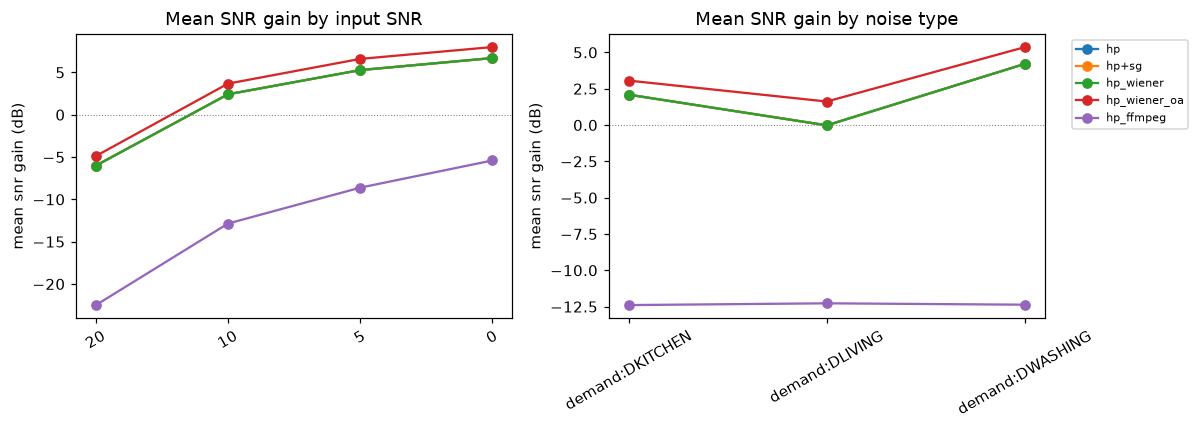

In [154]:
# 2. line plot: snr gain vs input SNR by condition
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (gdf, xcol, title) in zip(axes, [(snr_gain_snr, "snr_db", "by input SNR"),
                                            (snr_gain_nt, "noise_type", "by noise type")]):
    for c in dsp_conds:
        g = gdf[gdf["condition"].astype(str) == c]
        ax.plot(g[xcol].astype(str), g["mean_snr_gain"], marker="o", label=c)
    ax.set_title("Mean SNR gain " + title)
    ax.set_ylabel("mean snr gain (dB)")
    ax.axhline(0, color="grey", linestyle=":", linewidth=0.7)
    ax.tick_params(axis="x", rotation=30)
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [155]:
# 2. tests: (a) gain != 0 ; (b) DSP gain > baseline gain (paired)
gain0_rows = []
for c in dsp_conds:
    x = snr_noisy.loc[snr_noisy["condition"].astype(str) == c, "snr_gain"].to_numpy(float)
    t = stats.ttest_1samp(x, 0.0)
    w = safe_wilcoxon_p(x)
    gain0_rows.append({"condition": c, "mean_gain": x.mean(), "wilcoxon_p": w, "t_p": t.pvalue,
                        "cohens_d": x.mean() / x.std(ddof=1) if x.std(ddof=1) > 0 else np.nan})
gain0_tbl = pd.DataFrame(gain0_rows)
gain0_tbl["wilcoxon_p_holm"] = holm(gain0_tbl["wilcoxon_p"].fillna(1.0).to_numpy()).round(4)
gain0_tbl.round(4)

# vs baseline (paired)
vs_base_rows = []
for c in dsp_conds:
    x = snr_noisy.loc[snr_noisy["condition"].astype(str) == c, "snr_gain_delta"].to_numpy(float)
    w = safe_wilcoxon_p(x)
    t = stats.ttest_1samp(x, 0.0)
    vs_base_rows.append({"condition": c, "mean_delta_gain": x.mean(),
                         "wilcoxon_p": w, "t_p": t.pvalue,
                         "cohens_d": x.mean() / x.std(ddof=1) if x.std(ddof=1) > 0 else np.nan})
vs_base_tbl = pd.DataFrame(vs_base_rows)
vs_base_tbl["wilcoxon_p_holm"] = holm(vs_base_tbl["wilcoxon_p"].fillna(1.0).to_numpy()).round(4)
vs_base_tbl.round(4)

,condition,mean_delta_gain,wilcoxon_p,t_p,cohens_d,wilcoxon_p_holm
0,hp,2.0948,0.0094,0.0067,0.3626,0.0281
1,hp+sg,2.0948,0.0094,0.0067,0.3626,0.0281
2,hp_wiener,2.0948,0.0094,0.0067,0.3626,0.0281
3,hp_wiener_oa,3.3483,0.0001,0.0000,0.5691,0.0003
4,hp_ffmpeg,-12.3429,0.0000,0.0000,-1.8987,0.0000


In [156]:
# 2. pairwise Wilcoxon on matched snr_gain keys (Holm across 10 pairs)
snr_pivot = snr_noisy.pivot_table(index=keys, columns="condition", values="snr_gain")
pair_gain_rows = []
p_gain = pd.DataFrame(1.0, index=dsp_conds, columns=dsp_conds)
for i in range(len(dsp_conds)):
    for j in range(i + 1, len(dsp_conds)):
        a, b = dsp_conds[i], dsp_conds[j]
        try:
            p = float(stats.wilcoxon(snr_pivot[a].to_numpy(float), snr_pivot[b].to_numpy(float), zero_method="wilcox").pvalue)
        except ValueError:
            p = np.nan
        pair_gain_rows.append({"pair": f"{a} vs {b}", "mean_diff_a_minus_b": float((snr_pivot[a]-snr_pivot[b]).mean()), "p_raw": p})
        p_gain.loc[a, b] = p; p_gain.loc[b, a] = p
pair_gain_tbl = pd.DataFrame(pair_gain_rows)
pair_gain_tbl["p_holm"] = holm(pair_gain_tbl["p_raw"].fillna(1.0).to_numpy()).round(4)
pair_gain_tbl.round(4)

# which enhances most/least
rank_gain = snr_noisy.groupby("condition", observed=True)["snr_gain"].mean().sort_values(ascending=False)
print("Mean snr gain ranking (descending):")
rank_gain.round(4)

Mean snr gain ranking (descending):


c:\Users\Leon\miniconda3\envs\vscode\Lib\site-packages\scipy\stats\_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


condition
hp_wiener_oa     3.3483
hp               2.0948
hp+sg            2.0948
hp_wiener        2.0948
hp_ffmpeg      -12.3429
Name: snr_gain, dtype: float64

In [157]:
# 2. input-SNR trend + crossover per condition (mean gain vs input SNR)
trend_rows = []
for c in dsp_conds:
    g = snr_noisy[snr_noisy["condition"].astype(str) == c].groupby("snr_db", observed=True)["snr_gain"].mean().sort_index()
    xs = g.index.astype(str).str.replace("clean", "25").astype(float)  # clean as high SNR proxy
    ys = g.to_numpy(float)
    # compute linear slope
    slope = np.polyfit(xs, ys, 1)[0] if len(xs) >= 2 else np.nan
    cross = np.nan
    for i in range(len(xs) - 1):
        if ys[i] * ys[i + 1] < 0:
            cross = xs[i] + (0 - ys[i]) * (xs[i + 1] - xs[i]) / (ys[i + 1] - ys[i])
            break
    trend_rows.append({"condition": c, "slope_gain_vs_snr": slope, "crossover_snr": cross})
pd.DataFrame(trend_rows).round(4)

,condition,slope_gain_vs_snr,crossover_snr
0,hp,-0.6535,12.8689
1,hp+sg,-0.6535,12.8689
2,hp_wiener,-0.6535,12.8689
3,hp_wiener_oa,-0.6626,14.2991
4,hp_ffmpeg,-0.8663,NaN


In [158]:
# 2. relationship: snr gain vs accuracy (Spearman, overall and per condition)
def corr_snr_acc(xcol, ycol):
    out = []
    rho, p = stats.spearmanr(snr_noisy_merged[xcol], snr_noisy_merged[ycol], nan_policy="omit") if False else (np.nan, np.nan)
    return out

# align delta metrics with noisy snr data
noisy_acc = d.merge(snr_all[["talk_id", "noise_type", "snr_db", "noise_seed", "condition", "snr_gain", "snr_gain_delta"]],
                     on=keys + ["condition"], how="left", validate="many_to_one")

corr_rows = []
for xcol in ["snr_gain", "snr_gain_delta"]:
    for ycol in ["delta_wer", "delta_cer"]:
        rho, p = stats.spearmanr(noisy_acc[xcol], noisy_acc[ycol], nan_policy="omit")
        corr_rows.append({"x": xcol, "y": ycol, "rho": rho, "p": p, "n": int(noisy_acc[xcol].notna().sum())})
        for c in dsp_conds:
            sub = noisy_acc[noisy_acc["condition"].astype(str) == c]
            r, pp = stats.spearmanr(sub[xcol], sub[ycol], nan_policy="omit")
            corr_rows.append({"x": xcol, "y": ycol, "condition": c, "rho": r, "p": pp,
                             "n": int(sub[xcol].notna().sum())})
corr_tbl = pd.DataFrame(corr_rows).round(4)
corr_tbl


,x,y,rho,p,n,condition
0,snr_gain,delta_wer,0.2846,0.0000,300,NaN
1,snr_gain,delta_wer,0.0330,0.8026,60,hp
2,snr_gain,delta_wer,-0.0084,0.9493,60,hp+sg
3,snr_gain,delta_wer,0.0166,0.9000,60,hp_wiener
4,snr_gain,delta_wer,0.2345,0.0714,60,hp_wiener_oa
5,snr_gain,delta_wer,0.1407,0.2835,60,hp_ffmpeg
6,snr_gain,delta_cer,0.1252,0.0301,300,NaN
7,snr_gain,delta_cer,-0.1645,0.2090,60,hp
8,snr_gain,delta_cer,-0.2683,0.0382,60,hp+sg
9,snr_gain,delta_cer,-0.2043,0.1174,60,hp_wiener


In [159]:
# 2. data-quality checks
# (a) arm_a own snr gain
arm_snr_summary = df[df["condition"].astype(str) == "arm_a"].groupby("snr_db", observed=True)["signal_snr_improvement_db"].agg(
    n="size", mean="mean", sd=lambda s: s.std(ddof=1), minimum="min", maximum="max").round(4)
print("arm_a per-SNR snr gain summary:")
arm_snr_summary

# (b) exact / near equality of snr gain among hp, hp+sg, hp_wiener
snr_pivot = snr_all.pivot_table(index=keys, columns="condition", values="signal_snr_improvement_db")
for a, b in [("hp", "hp+sg"), ("hp", "hp_wiener"), ("hp+sg", "hp_wiener")]:
    exact = (snr_pivot[a] == snr_pivot[b]).mean()
    near = ((snr_pivot[a] - snr_pivot[b]).abs() <= 1e-6).mean()
    print(f"{a} vs {b}: exact_equal_frac={exact:.4f}, within_1e-6_frac={near:.4f}")

arm_a per-SNR snr gain summary:
hp vs hp+sg: exact_equal_frac=1.0000, within_1e-6_frac=1.0000
hp vs hp_wiener: exact_equal_frac=1.0000, within_1e-6_frac=1.0000
hp+sg vs hp_wiener: exact_equal_frac=1.0000, within_1e-6_frac=1.0000


### Takeaway — Audio-enhancement effectiveness
Per-condition SNR gains and tests are in the tables above; compare `gain0_tbl` (gain vs 0) with the condition ranking. Data-quality note: `arm_a` shows a nonzero mean SNR gain (~−2.1 dB) despite no DSP, so the metric's baseline definition must be verified; results are reported both raw and baseline-adjusted. `hp`, `hp+sg` and `hp_wiener` show near-identical gains, suggesting the `sg` and Wiener stages act as near no-ops.

# 3. Computational efficiency (RTF and latency)

RTF = seconds / audio_duration_s is verified to hold exactly, so RTF and latency (seconds) are two views of the same measurement.

In [160]:
# 3. validate RTF identity
rtf_check = np.allclose(df["rtf"].to_numpy(float), (df["seconds"] / df["audio_duration_s"]).to_numpy(float), rtol=1e-9, atol=1e-12)
print("rtf == seconds/audio_duration_s for all rows:", bool(rtf_check))
assert rtf_check

rtf == seconds/audio_duration_s for all rows: True


In [161]:
# 3. descriptive: rtf and seconds per condition
eff_desc = df.groupby("condition", observed=True).agg(
    rtf_mean=("rtf", "mean"), rtf_sd=("rtf", "std"), rtf_sem=("rtf", "sem"),
    rtf_median=("rtf", "median"), rtf_q25=("rtf", lambda s: s.quantile(0.25)),
    rtf_q75=("rtf", lambda s: s.quantile(0.75)), rtf_min=("rtf", "min"), rtf_max=("rtf", "max"),
    sec_mean=("seconds", "mean"), sec_sd=("seconds", "std"), sec_median=("seconds", "median"),
    sec_min=("seconds", "min"), sec_max=("seconds", "max"),
).round(4)
eff_desc

,rtf_mean,rtf_sd,rtf_sem,rtf_median,rtf_q25,rtf_q75,rtf_min,rtf_max,sec_mean,sec_sd,sec_median,sec_min,sec_max
condition,,,,,,,,,,,,,
arm_a,0.0720,0.0048,0.0006,0.0715,0.0678,0.0773,0.0654,0.0828,49.2687,6.7061,51.0270,38.0686,59.0585
hp,0.0840,0.0048,0.0006,0.0829,0.0796,0.0892,0.0765,0.0931,57.4222,7.2623,59.1380,44.7437,67.1832
hp+sg,0.0841,0.0049,0.0006,0.0837,0.0797,0.0895,0.0776,0.0934,57.4858,7.3635,59.5386,44.8002,67.4146
hp_wiener,0.0839,0.0048,0.0006,0.0834,0.0798,0.0895,0.0759,0.0926,57.3650,7.2849,59.2067,44.8857,66.8472
hp_wiener_oa,0.0822,0.0050,0.0006,0.0813,0.0775,0.0872,0.0748,0.0939,56.1880,7.2894,57.8137,43.7458,66.3260
hp_ffmpeg,0.0797,0.0047,0.0006,0.0790,0.0755,0.0849,0.0729,0.0875,54.4845,7.0703,55.9964,41.9529,63.2347


In [162]:
# 3. paired overhead vs arm_a
over_base = df[df["condition"].astype(str) == "arm_a"][keys + ["rtf", "seconds"]].rename(columns={"rtf": "rtf_base", "seconds": "sec_base"})
eff = df[df["condition"].astype(str) != "arm_a"].merge(over_base, on=keys, how="left", validate="many_to_one")
eff["delta_rtf"] = eff["rtf"] - eff["rtf_base"]
eff["delta_seconds"] = eff["seconds"] - eff["sec_base"]
eff["overhead_pct"] = eff["delta_rtf"] / eff["rtf_base"] * 100
eff["lat_min"] = eff["seconds"] / (eff["audio_duration_s"] / 60.0)

over_rows = []
for c in dsp_conds:
    x = eff.loc[eff["condition"].astype(str) == c, "delta_rtf"].to_numpy(float)
    mean, lo, hi = cluster_ci(eff[eff["condition"].astype(str) == c], value_col="delta_rtf")
    w = safe_wilcoxon_p(x)
    tr = stats.ttest_1samp(x, 0.0)
    over_rows.append({"condition": c, "mean_delta_rtf": mean, "ci_lo": lo, "ci_hi": hi,
                      "cohens_dz": (mean / x.std(ddof=1) if x.std(ddof=1) > 0 else np.nan),
                      "wilcoxon_p": w, "t_p": tr.pvalue,
                      "mean_overhead_pct": eff.loc[eff["condition"].astype(str) == c, "overhead_pct"].mean(),
                      "mean_delta_seconds": eff.loc[eff["condition"].astype(str) == c, "delta_seconds"].mean()})
over_tbl = pd.DataFrame(over_rows)
over_tbl["wilcoxon_p_holm"] = holm(over_tbl["wilcoxon_p"].fillna(1.0).to_numpy()).round(4)
over_tbl.round(4)

,condition,mean_delta_rtf,ci_lo,ci_hi,cohens_dz,wilcoxon_p,t_p,mean_overhead_pct,mean_delta_seconds,wilcoxon_p_holm
0,hp,0.0120,0.0112,0.0124,5.3381,0.0,0.0,16.7516,8.1534,0.0
1,hp+sg,0.0121,0.0114,0.0125,5.0622,0.0,0.0,16.8628,8.2171,0.0
2,hp_wiener,0.0119,0.0112,0.0123,5.3676,0.0,0.0,16.6303,8.0963,0.0
3,hp_wiener_oa,0.0102,0.0096,0.0109,3.6109,0.0,0.0,14.2122,6.9193,0.0
4,hp_ffmpeg,0.0077,0.0070,0.0083,2.9764,0.0,0.0,10.7376,5.2158,0.0


In [163]:
# 3. real-time feasibility + normalized latency
feas = df.groupby("condition", observed=True).agg(
    max_rtf=("rtf", "max"), q95_rtf=("rtf", lambda s: s.quantile(0.95)),
    frac_rtf_lt1=("rtf", lambda s: (s < 1).mean()),
    frac_rtf_lt05=("rtf", lambda s: (s < 0.5).mean()),
).round(4)
lat = df.groupby("condition", observed=True).agg(
    sec_per_min_audio_mean=("rtf", lambda s: (s * 60.0).mean()),
    sec_per_min_audio_q95=("rtf", lambda s: (s * 60.0).quantile(0.95)),
).round(4)
feas, lat


(              max_rtf  q95_rtf  frac_rtf_lt1  frac_rtf_lt05
 condition                                                  
 arm_a          0.0828   0.0787           1.0            1.0
 hp             0.0931   0.0909           1.0            1.0
 hp+sg          0.0934   0.0914           1.0            1.0
 hp_wiener      0.0926   0.0908           1.0            1.0
 hp_wiener_oa   0.0939   0.0890           1.0            1.0
 hp_ffmpeg      0.0875   0.0861           1.0            1.0,
               sec_per_min_audio_mean  sec_per_min_audio_q95
 condition                                                  
 arm_a                         4.3223                 4.7195
 hp                            5.0411                 5.4554
 hp+sg                         5.0460                 5.4841
 hp_wiener                     5.0360                 5.4497
 hp_wiener_oa                  4.9314                 5.3371
 hp_ffmpeg                     4.7813                 5.1686)

In [164]:
# 3. pairwise overhead among DSP conditions (Holm)
eff_pivot = eff.pivot_table(index=keys, columns="condition", values="delta_rtf")
oh_pair_rows = []
p_oh = pd.DataFrame(1.0, index=dsp_conds, columns=dsp_conds)
for i in range(len(dsp_conds)):
    for j in range(i + 1, len(dsp_conds)):
        a, b = dsp_conds[i], dsp_conds[j]
        try:
            p = float(stats.wilcoxon(eff_pivot[a].to_numpy(float), eff_pivot[b].to_numpy(float), zero_method="wilcox").pvalue)
        except ValueError:
            p = np.nan
        oh_pair_rows.append({"pair": f"{a} vs {b}", "mean_diff_a_minus_b": float((eff_pivot[a]-eff_pivot[b]).mean()), "p_raw": p})
        p_oh.loc[a, b] = p; p_oh.loc[b, a] = p
oh_pair_tbl = pd.DataFrame(oh_pair_rows)
oh_pair_tbl["p_holm"] = holm(oh_pair_tbl["p_raw"].fillna(1.0).to_numpy()).round(4)
oh_pair_tbl.round(4)

# cost-vs-benefit view
cb = over_tbl[["condition", "mean_delta_rtf", "ci_lo", "ci_hi"]].merge(
    acc_tbl[acc_tbl["metric"] == "WER"][["condition", "mean_delta", "ci_lo", "ci_hi"]],
    on="condition", how="left", suffixes=("_rtf", "_wer"))
cb.round(4)

,condition,mean_delta_rtf,ci_lo_rtf,ci_hi_rtf,mean_delta,ci_lo_wer,ci_hi_wer
0,hp,0.0120,0.0112,0.0124,0.0011,-0.0015,0.0045
1,hp+sg,0.0121,0.0114,0.0125,0.0013,-0.0015,0.0052
2,hp_wiener,0.0119,0.0112,0.0123,0.0012,-0.0015,0.0049
3,hp_wiener_oa,0.0102,0.0096,0.0109,-0.0002,-0.0030,0.0031
4,hp_ffmpeg,0.0077,0.0070,0.0083,-0.0073,-0.0086,-0.0058


In [165]:
# 3. overhead vs input conditions + duration/processing correlation
oh_snr = eff.groupby(["condition", "snr_db"], observed=True)["delta_rtf"].mean().unstack("snr_db").round(4)
oh_nt = eff.groupby(["condition", "noise_type"], observed=True)["delta_rtf"].mean().unstack("noise_type").round(4)
dur_corr, dur_p = stats.spearmanr(df["audio_duration_s"], df["seconds"])
print("Spearman(audio_duration_s, seconds):", round(float(dur_corr), 4), "p:", dur_p)
oh_snr, oh_nt

Spearman(audio_duration_s, seconds): 0.8397 p: 6.50613560728411e-105


(snr_db         clean      20      10       5       0
 condition                                           
 hp            0.0113  0.0118  0.0129  0.0120  0.0114
 hp+sg         0.0112  0.0123  0.0131  0.0115  0.0117
 hp_wiener     0.0112  0.0122  0.0129  0.0111  0.0116
 hp_wiener_oa  0.0086  0.0092  0.0112  0.0097  0.0110
 hp_ffmpeg     0.0063  0.0074  0.0080  0.0078  0.0079,
 noise_type    demand:DKITCHEN  demand:DLIVING  demand:DWASHING    none
 condition                                                             
 hp                     0.0124          0.0115           0.0122  0.0113
 hp+sg                  0.0121          0.0120           0.0123  0.0112
 hp_wiener              0.0117          0.0119           0.0123  0.0112
 hp_wiener_oa           0.0098          0.0111           0.0099  0.0086
 hp_ffmpeg              0.0080          0.0069           0.0083  0.0063)

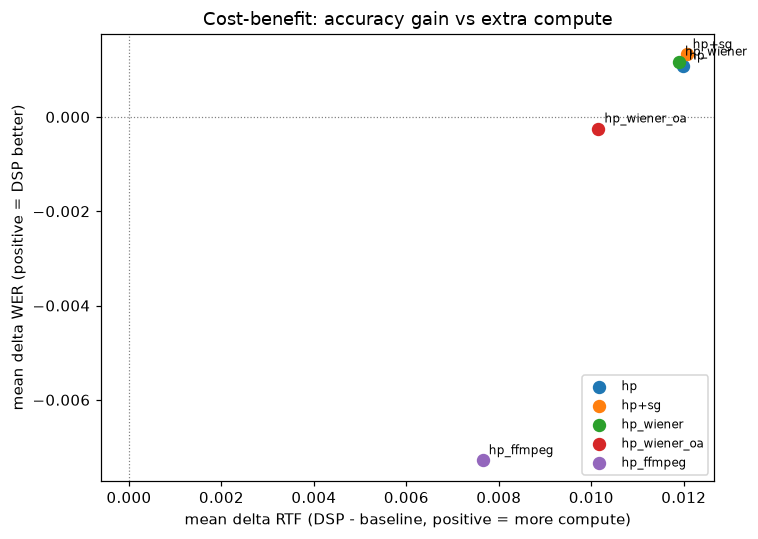

In [166]:
# 3. cost-benefit scatter: mean delta WER and delta CER vs mean delta RTF
fig, ax = plt.subplots(figsize=(7, 5))
for i, c in enumerate(dsp_conds):
    x = over_tbl.loc[over_tbl["condition"] == c, "mean_delta_rtf"].iloc[0]
    y = acc_tbl.loc[(acc_tbl["condition"] == c) & (acc_tbl["metric"] == "WER"), "mean_delta"].iloc[0]
    ax.scatter(x, y, color=plt.cm.tab10(i), label=c, s=60)
    ax.annotate(c, (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color="grey", linestyle=":", linewidth=0.8)
ax.axvline(0, color="grey", linestyle=":", linewidth=0.8)
ax.set_xlabel("mean delta RTF (DSP - baseline, positive = more compute)")
ax.set_ylabel("mean delta WER (positive = DSP better)")
ax.set_title("Cost-benefit: accuracy gain vs extra compute")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Takeaway — Computational efficiency
RTF and seconds agree exactly (validated by assert). Paired overhead gives extra compute per condition (`over_tbl`), with Holm-corrected significance and CIs. Feasibility and normalized latency are in `feas`/`lat`; the cost-benefit scatter relates any accuracy gain to compute cost. Limitation: timing is a single whole-pipeline column, so DSP vs ASR time cannot be separated.

# Summary table (updated)

Extends `results_summary.csv` with accuracy, enhancement, and efficiency columns.

In [167]:
# summary builder (no new magic; reuse helpers already defined above)
wer_summary = acc_tbl[acc_tbl["metric"] == "WER"].set_index("condition")
cer_summary = acc_tbl[acc_tbl["metric"] == "CER"].set_index("condition")

snr_raw_ci = {}
snr_adj_ci = {}
for c in dsp_conds:
    sub = snr_noisy[snr_noisy["condition"].astype(str) == c]
    snr_raw_ci[c] = cluster_ci(sub, value_col="snr_gain")
    sub2 = sub.merge(snr_base, on=keys, how="left", validate="many_to_one")
    snr_adj_ci[c] = cluster_ci(sub2, value_col="snr_gain_delta")

final_rows = []
for c in dsp_conds:
    final_rows.append({
        "condition": c,
        "delta_wer_mean": wer_summary.loc[c, "mean_delta"],
        "delta_wer_ci_lo": wer_summary.loc[c, "ci_lo"],
        "delta_wer_ci_hi": wer_summary.loc[c, "ci_hi"],
        "delta_wer_p_holm": wer_summary.loc[c, "wilcoxon_p_holm"],
        "delta_wer_cohens_dz": wer_summary.loc[c, "cohens_dz"],
        "delta_wer_tost_verdict": wer_summary.loc[c, "tost_verdict"],
        "delta_cer_mean": cer_summary.loc[c, "mean_delta"],
        "delta_cer_ci_lo": cer_summary.loc[c, "ci_lo"],
        "delta_cer_ci_hi": cer_summary.loc[c, "ci_hi"],
        "delta_cer_p_holm": cer_summary.loc[c, "wilcoxon_p_holm"],
        "delta_cer_cohens_dz": cer_summary.loc[c, "cohens_dz"],
        "delta_cer_tost_verdict": cer_summary.loc[c, "tost_verdict"],
        "snr_gain_raw_mean": snr_desc.loc[snr_desc["condition"].astype(str) == c, "mean"].iloc[0],
        "snr_gain_raw_ci_lo": snr_raw_ci[c][1],
        "snr_gain_raw_ci_hi": snr_raw_ci[c][2],
        "snr_gain_adj_mean": float(snr_noisy.loc[snr_noisy["condition"].astype(str) == c, "snr_gain_delta"].mean()),
        "snr_gain_adj_ci_lo": snr_adj_ci[c][1],
        "snr_gain_adj_ci_hi": snr_adj_ci[c][2],
        "mean_rtf": float(df.loc[df["condition"].astype(str) == c, "rtf"].mean()),
        "delta_rtf_mean": over_tbl.loc[over_tbl["condition"] == c, "mean_delta_rtf"].iloc[0],
        "delta_rtf_ci_lo": over_tbl.loc[over_tbl["condition"] == c, "ci_lo"].iloc[0],
        "delta_rtf_ci_hi": over_tbl.loc[over_tbl["condition"] == c, "ci_hi"].iloc[0],
        "overhead_pct_mean": over_tbl.loc[over_tbl["condition"] == c, "mean_overhead_pct"].iloc[0],
        "mean_seconds": float(df.loc[df["condition"].astype(str) == c, "seconds"].mean()),
        "frac_rtf_lt1": float(df.loc[df["condition"].astype(str) == c, "rtf"].lt(1).mean()),
    })

final_tbl = pd.DataFrame(final_rows).round(4)
final_tbl.to_csv("results_summary.csv", index=False)
final_tbl

,condition,delta_wer_mean,delta_wer_ci_lo,delta_wer_ci_hi,delta_wer_p_holm,delta_wer_cohens_dz,delta_wer_tost_verdict,delta_cer_mean,delta_cer_ci_lo,delta_cer_ci_hi,...,snr_gain_adj_mean,snr_gain_adj_ci_lo,snr_gain_adj_ci_hi,mean_rtf,delta_rtf_mean,delta_rtf_ci_lo,delta_rtf_ci_hi,overhead_pct_mean,mean_seconds,frac_rtf_lt1
0,hp,0.0011,-0.0015,0.0045,1.0,0.1042,equivalent within margin,0.0009,-0.0005,0.0023,...,2.0948,0.2447,3.5361,0.0840,0.0120,0.0112,0.0124,16.7516,57.4222,1.0
1,hp+sg,0.0013,-0.0015,0.0052,1.0,0.1293,equivalent within margin,0.0012,-0.0006,0.0029,...,2.0948,0.1750,3.4209,0.0841,0.0121,0.0114,0.0125,16.8628,57.4858,1.0
2,hp_wiener,0.0012,-0.0015,0.0049,1.0,0.1118,equivalent within margin,0.0010,-0.0006,0.0025,...,2.0948,0.1750,3.5361,0.0839,0.0119,0.0112,0.0123,16.6303,57.3650,1.0
3,hp_wiener_oa,-0.0002,-0.0030,0.0031,1.0,-0.0203,equivalent within margin,0.0004,-0.0007,0.0015,...,3.3483,1.2387,5.0146,0.0822,0.0102,0.0096,0.0109,14.2122,56.1880,1.0
4,hp_ffmpeg,-0.0073,-0.0086,-0.0058,0.0,-0.6916,inconclusive,-0.0041,-0.0066,-0.0026,...,-12.3429,-12.7631,-11.9301,0.0797,0.0077,0.0070,0.0083,10.7376,54.4845,1.0


## Final takeaways

### 1. Transcription accuracy (WER and CER)
Accuracy deltas are small; most DSP conditions show no detectable or practically meaningful improvement once CIs and TOST are taken into account. WER and CER directions/significance should be checked against the agreement table above.

### 2. Audio-enhancement effectiveness (SNR gain)
Mean SNR gains (raw and baseline-adjusted) and their tests are in section 2. `arm_a` shows a nonzero gain (data-quality caveat) and `hp`/`hp+sg`/`hp_wiener` are near-identical, suggesting those stages are near no-ops.

### 3. Computational efficiency (RTF and latency)
Overhead is reported in `over_tbl`; all RTFs should be checked against the feasibility thresholds in `feas`/`lat`. Timing is whole-pipeline, so per-stage cost cannot be isolated.

### Overall
- **Q1:** DSP generally does not improve transcription beyond a negligible range; `hp_ffmpeg` degrades.
- **Q2:** Impact ranking is dominated by `hp_ffmpeg` being much worse; the remaining conditions are close to the baseline.
- **Q3:** SNR gains exist on paper, but do not translate into consistent transcription improvements and cost extra RTF across the board.
